Section 1

In [5]:
!pip install -q catboost shap

import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
SEED = 42
np.random.seed(SEED)

Section 2

In [6]:
df_raw = pd.read_csv('Colombo_Sri_Lanka.csv')
print('Shape:', df_raw.shape)
display(df_raw.head())
df_raw.info()
print('\nMissing values:\n', df_raw.isna().sum())
display(df_raw.describe().round(0))

Shape: (3179, 7)


,id,price_lkr,location,bedrooms,bathrooms,area_sqft,posted_time
0,sa1142-2br-apartment-for-sale-in-vip-residenci...,15000000.0,Battaramulla,2.0,1.0,800.0,11 Sep 4:39 pm
1,cinnamon-lifecolombo2-unfurnished-penthouse-ap...,750000000.0,"Cinnamon Life, Colombo 02",5.0,5.0,4700.0,10 Sep 4:51 pm
2,sds-676valuable-luxury-brand-new-modern-apartm...,62000000.0,kotte,2.0,2.0,796.0,11 Sep 6:30 pm
3,cinnamon-life-furnished-apartment-for-sale-a11...,336000000.0,"Cinnamon Life, Colobmo 02",3.0,2.0,1650.0,11 Sep 5:55 pm
4,brand-new-apartment-for-sale-at-marina-square-...,96000000.0,NaN,3.0,2.0,1292.0,11 Sep 5:54 pm


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3179 entries, 0 to 3178
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           3179 non-null   object 
 1   price_lkr    3176 non-null   float64
 2   location     1901 non-null   object 
 3   bedrooms     3178 non-null   float64
 4   bathrooms    3178 non-null   float64
 5   area_sqft    3178 non-null   float64
 6   posted_time  3178 non-null   object 
dtypes: float64(4), object(3)
memory usage: 174.0+ KB

Missing values:
 id                0
price_lkr         3
location       1278
bedrooms          1
bathrooms         1
area_sqft         1
posted_time       1
dtype: int64


,price_lkr,bedrooms,bathrooms,area_sqft
count,3.176000e+03,3178.0,3178.0,3178.0
mean,9.270131e+07,3.0,2.0,1437.0
std,9.648210e+07,13.0,1.0,920.0
min,3.000000e+00,1.0,1.0,0.0
25%,4.500000e+07,2.0,2.0,1000.0
50%,6.800000e+07,3.0,2.0,1259.0
75%,1.050000e+08,3.0,3.0,1630.0
max,1.700000e+09,715.0,10.0,20000.0


Section 3

In [7]:
df = df_raw.copy()
log = [('Raw data', len(df))]

# 1. One searchable text field: location + ad title (slug).
#    The '-for-sale-colombo-3' ending is ikman's slug counter, not a location.
df['slug'] = (df['id'].str.lower()
              .str.replace(r'-for-sale-colombo(-\d+)?$', '', regex=True)
              .str.replace('-', ' '))
df['text'] = df['location'].fillna('').str.lower() + ' ' + df['slug']

# 2. Remove rentals, missing values, junk and impossible values
df = df[~df['slug'].str.contains(r'\brent\b|\brental\b', regex=True)]
log.append(('Removed rental ads', len(df)))

df = df.dropna(subset=['price_lkr', 'bedrooms', 'bathrooms', 'area_sqft'])
df = df[df['price_lkr'] >= 5_000_000]
log.append(('Removed missing values / price < Rs 5M', len(df)))

df = df[df['bedrooms'].between(1, 10) &
        df['bathrooms'].between(1, 10) &
        df['area_sqft'].between(300, 10_000)]
log.append(('Removed impossible beds / baths / area', len(df)))

pps = df['price_lkr'] / df['area_sqft']
df = df[pps.between(10_000, 400_000)]          # catches typos (missing/extra zeros)
log.append(('Removed extreme price per sqft', len(df)))

# 3. Location -> zone
NAMED_ZONES = [   # checked first, in this order
    ('Colombo 01-02',       r'cinnamon life|tri ?zen|altair|one galle face|galle face|union place|slave island|colombo city centre'),
    ('Colombo 05',          r'havelock|trillium|narahenpita|kirulapone'),
    ('Colombo 03',          r'kollupitiya|kolpity'),
    ('Colombo 04-06',       r'wellawatt|wellavatt|bambalapitiya'),
    ('Colombo 08-12',       r'borella|maradana|dematagoda'),
    ('Rajagiriya',          r'rajagiriya|royal park|clearpoint|welikada'),
    ('Battaramulla/Kotte',  r'battaramulla|battramulla|kotte|pelawatte|thalawathugoda|nawala|koswatta|koswatha|ethul'),
    ('Athurugiriya/Malabe', r'athurugiriya|malabe|kaduwela|cresida|homagama|kottawa|elixia'),
    ('Dehiwala/Mt Lavinia', r'dehiwala|mount lavinia|mt lavinia|ratmalana|moratuwa|angulana'),
    ('Piliyandala',         r'piliyandala|kahathuduwa|canterbury'),
    ('Nugegoda',            r'nugegoda|kohuwala|boralesgamuwa|maharagama|wijerama'),
    ('Wattala/North',       r'wattala|kelaniya|ja ela|negombo|kiribathgoda|mattakkuliya'),
]
COLOMBO_NUM = {1: 'Colombo 01-02', 2: 'Colombo 01-02', 3: 'Colombo 03',
               4: 'Colombo 04-06', 5: 'Colombo 05', 6: 'Colombo 04-06', 7: 'Colombo 07',
               8: 'Colombo 08-12', 9: 'Colombo 08-12', 10: 'Colombo 08-12',
               11: 'Colombo 08-12', 12: 'Colombo 08-12',
               13: 'Colombo 13-15', 14: 'Colombo 13-15', 15: 'Colombo 13-15'}

def get_zone(text):
    for zone, pattern in NAMED_ZONES:
        if re.search(pattern, text):
            return zone
    m = re.search(r'colo?mbo\s*[- ]?0?(\d{1,2})\b', text)   # e.g. "colombo 07", "colombo-5"
    if m and int(m.group(1)) in COLOMBO_NUM:
        return COLOMBO_NUM[int(m.group(1))]
    if 'colombo' in text:
        return 'Colombo (unspecified)'
    return 'Other'

df['zone'] = df['text'].apply(get_zone)
rare = df['zone'].value_counts()[lambda s: s < 20].index      # too few rows to learn from
df.loc[df['zone'].isin(rare), 'zone'] = 'Other'

# 4. Remove duplicate re-posted ads
df = df.drop_duplicates(subset=['price_lkr', 'zone', 'bedrooms', 'bathrooms', 'area_sqft'])
log.append(('Removed duplicate re-posts', len(df)))

# 5. Keyword features from the ad title
KEYWORDS = {
    'is_luxury':    r'luxury|luxurious|prestige|premium',
    'is_furnished': r'(?<!un)furnished',
    'is_brand_new': r'brand ?new',
    'is_penthouse': r'penthouse',
    'is_sea_view':  r'sea view|seaview|ocean view|sea facing',
    'is_landmark':  r'cinnamon life|altair|one galle face|tri ?zen|havelock city|shangri|colombo city centre',
}
for col, pattern in KEYWORDS.items():
    df[col] = df['text'].str.contains(pattern, regex=True).astype(int)

# 6. Final features and target
df['bath_per_bed'] = df['bathrooms'] / df['bedrooms']
df['log_price'] = np.log(df['price_lkr'])
df = df.drop(columns=['posted_time', 'location', 'slug', 'text']).reset_index(drop=True)

# 7. Summary (copy this table into your report)
display(pd.DataFrame(log, columns=['Cleaning step', 'Rows remaining']))
print('Listings per zone:\n', df['zone'].value_counts())
print('\nKeyword flags:\n', df.filter(like='is_').sum())
df.to_csv('apartments_clean.csv', index=False)

,Cleaning step,Rows remaining
0,Raw data,3179
1,Removed rental ads,3160
2,Removed missing values / price < Rs 5M,3150
3,Removed impossible beds / baths / area,3138
4,Removed extreme price per sqft,3135
5,Removed duplicate re-posts,2025


Listings per zone:
 zone
Colombo 01-02            272
Colombo 03               227
Colombo 04-06            217
Dehiwala/Mt Lavinia      198
Rajagiriya               171
Colombo 05               160
Battaramulla/Kotte       143
Other                    142
Athurugiriya/Malabe      137
Piliyandala              109
Colombo 13-15             60
Colombo 08-12             60
Colombo 07                49
Colombo (unspecified)     45
Nugegoda                  35
Name: count, dtype: int64

Keyword flags:
 is_luxury       399
is_furnished    356
is_brand_new    211
is_penthouse     37
is_sea_view      54
is_landmark     212
dtype: int64


Section 4


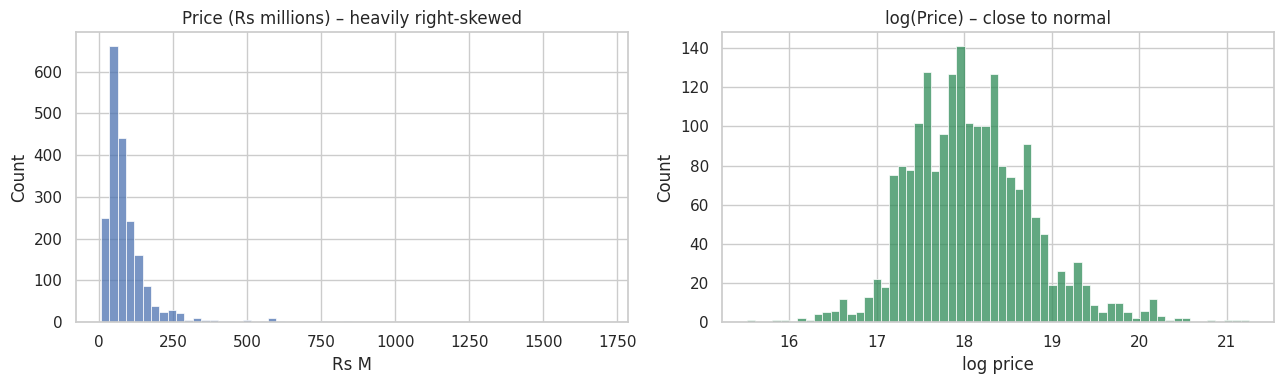

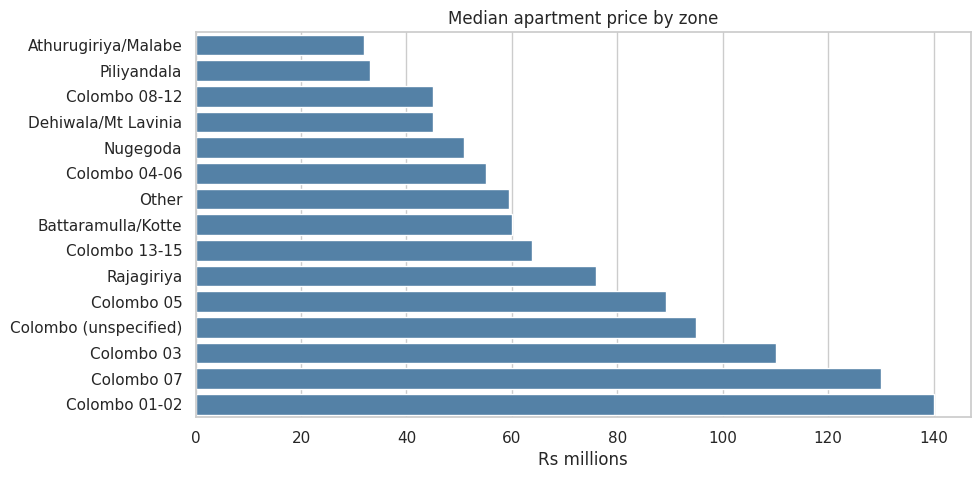

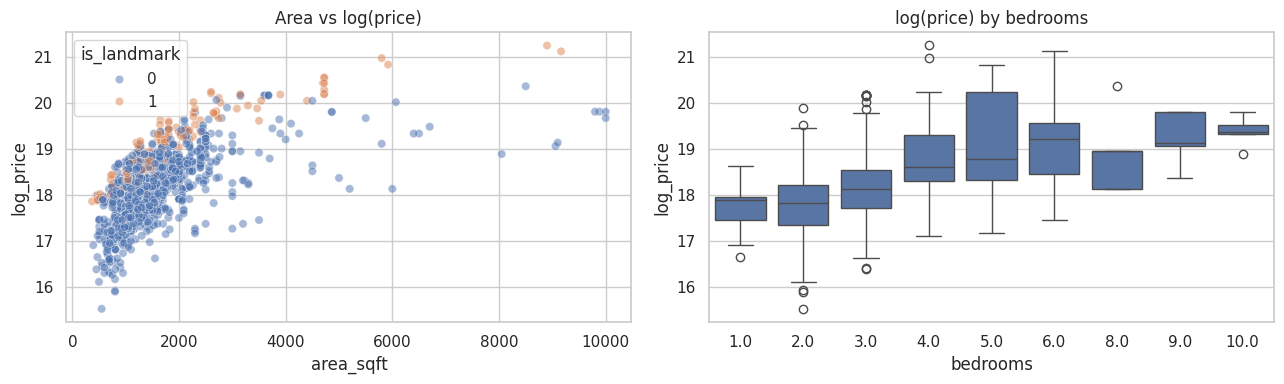

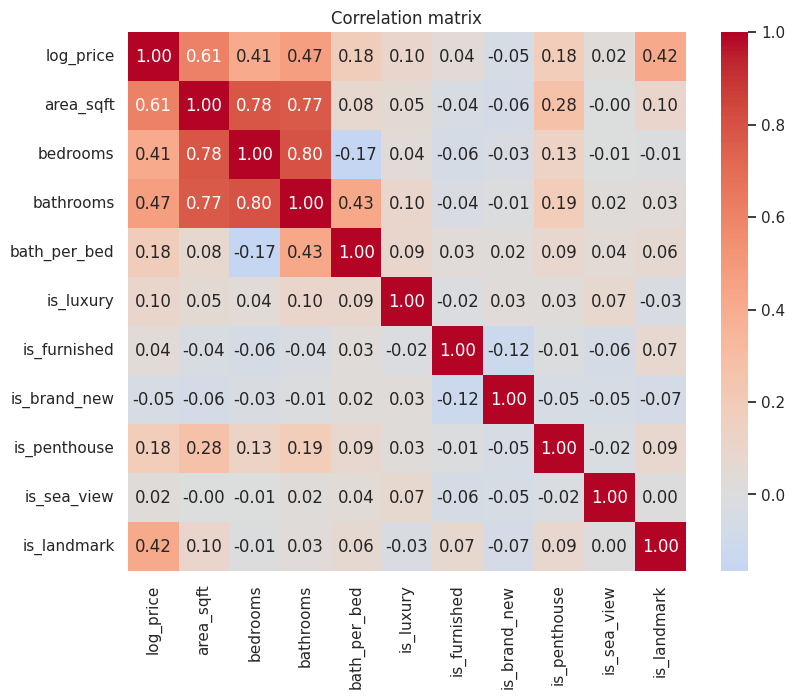

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['price_lkr'] / 1e6, bins=60, ax=ax[0]).set(title='Price (Rs millions) – heavily right-skewed', xlabel='Rs M')
sns.histplot(df['log_price'], bins=60, ax=ax[1], color='seagreen').set(title='log(Price) – close to normal', xlabel='log price')
plt.tight_layout(); plt.show()

order = df.groupby('zone')['price_lkr'].median().sort_values().index
plt.figure(figsize=(10, 5))
sns.barplot(data=df, y='zone', x=df['price_lkr'] / 1e6, order=order, estimator=np.median, errorbar=None, color='steelblue')
plt.title('Median apartment price by zone'); plt.xlabel('Rs millions'); plt.ylabel('')
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x='area_sqft', y='log_price', hue='is_landmark', alpha=0.5, ax=ax[0]).set(title='Area vs log(price)')
sns.boxplot(data=df, x='bedrooms', y='log_price', ax=ax[1]).set(title='log(price) by bedrooms')
plt.tight_layout(); plt.show()

num_cols = ['log_price', 'area_sqft', 'bedrooms', 'bathrooms', 'bath_per_bed'] + list(KEYWORDS)
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix'); plt.show()

Section 5

In [9]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
import time

FEATURES_NUM = ['area_sqft', 'bedrooms', 'bathrooms', 'bath_per_bed'] + list(KEYWORDS)

# One-hot version (for most models)
X = pd.get_dummies(df[FEATURES_NUM + ['zone']], columns=['zone'], dtype=int)
X.columns = X.columns.str.replace(r'[^A-Za-z0-9_]+', '_', regex=True)   # safe names for XGBoost/LightGBM
y = df['log_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=df['zone'])

# Raw-category version (for CatBoost native), same rows
X_cat = df[FEATURES_NUM + ['zone']]
Xc_train, Xc_test = X_cat.loc[X_train.index], X_cat.loc[X_test.index]

print('Train:', X_train.shape, ' Test:', X_test.shape)

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
results, models, preds = [], {}, {}

def evaluate(name, family, model, Xtr=None, Xte=None, cv=True):
    Xtr = X_train if Xtr is None else Xtr
    Xte = X_test if Xte is None else Xte
    cv_rmse = (-cross_val_score(model, Xtr, y_train, cv=kf,
                                scoring='neg_root_mean_squared_error').mean() if cv else np.nan)
    t = time.time(); model.fit(Xtr, y_train); fit_time = time.time() - t
    p = model.predict(Xte)
    actual, pred = np.exp(y_test), np.exp(p)                       # back to rupees
    results.append({
        'Model': name, 'Family': family,
        'CV RMSE (log)': cv_rmse,
        'Test RMSE (log)': np.sqrt(mean_squared_error(y_test, p)),
        'R² (log)': r2_score(y_test, p),
        'MAE (Rs M)': mean_absolute_error(actual, pred) / 1e6,
        'RMSE (Rs M)': np.sqrt(mean_squared_error(actual, pred)) / 1e6,
        'MAPE %': mean_absolute_percentage_error(actual, pred) * 100,
        'Fit time (s)': fit_time})
    models[name], preds[name] = model, p
    r = results[-1]
    print(f"{name:<26} R²={r['R² (log)']:.3f}  MAE=Rs {r['MAE (Rs M)']:.1f}M  MAPE={r['MAPE %']:.1f}%")

Train: (1620, 25)  Test: (405, 25)


Section 6.0 Model definitions and baseline

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, StackingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

def make_rf():   return RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=SEED)
def make_xgb():  return XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5, subsample=0.8,
                                     colsample_bytree=0.8, random_state=SEED, n_jobs=-1)
def make_lgbm(): return LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31,
                                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                      random_state=SEED, verbose=-1)
def make_cat():  return CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=6,
                                          random_seed=SEED, verbose=0)
def make_mlp():  return TransformedTargetRegressor(
                     regressor=make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=2000,
                                      early_stopping=True, random_state=SEED)),
                     transformer=StandardScaler())

evaluate('Linear Regression', 'Baseline', make_pipeline(StandardScaler(), LinearRegression()))

Linear Regression          R²=0.736  MAE=Rs 33.5M  MAPE=30.5%


6.1 Bagging


In [11]:
evaluate('Bagging (Decision Trees)', 'Bagging',
         BaggingRegressor(DecisionTreeRegressor(), n_estimators=300, n_jobs=-1, random_state=SEED))
evaluate('Random Forest', 'Bagging', make_rf())


Bagging (Decision Trees)   R²=0.842  MAE=Rs 19.5M  MAPE=19.9%
Random Forest              R²=0.842  MAE=Rs 19.5M  MAPE=19.9%


6.2 Boosting


In [13]:
evaluate('AdaBoost', 'Boosting',
         AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=300,
                           learning_rate=0.05, random_state=SEED))
evaluate('Gradient Boosting', 'Boosting',
         GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                                   subsample=0.8, random_state=SEED))
evaluate('XGBoost', 'Boosting', make_xgb())
evaluate('LightGBM', 'Boosting', make_lgbm())
evaluate('CatBoost (one-hot)', 'Boosting', make_cat())
evaluate('CatBoost (native zone)', 'Boosting',
         CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=6, random_seed=SEED,
                           verbose=0, cat_features=['zone']),
         Xtr=Xc_train, Xte=Xc_test)

CatBoost (native zone)     R²=0.840  MAE=Rs 20.6M  MAPE=20.9%


6.3 Stacking

In [14]:
stack = StackingRegressor(
    estimators=[('rf', make_rf()), ('xgb', make_xgb()), ('lgbm', make_lgbm()), ('cat', make_cat())],
    final_estimator=RidgeCV(), cv=5, n_jobs=-1)
evaluate('Stacking (RF+XGB+LGBM+Cat)', 'Stacking', stack, cv=False)

print('\nMeta-model weights:',
      dict(zip(['RF', 'XGB', 'LGBM', 'Cat'], stack.final_estimator_.coef_.round(3))))

Stacking (RF+XGB+LGBM+Cat) R²=0.858  MAE=Rs 19.7M  MAPE=20.0%

Meta-model weights: {'RF': np.float64(0.293), 'XGB': np.float64(0.203), 'LGBM': np.float64(0.178), 'Cat': np.float64(0.326)}


6.4 Hybrid: Random Forest + ANN

In [15]:
from sklearn.base import BaseEstimator, RegressorMixin, clone

class WeightedBlend(BaseEstimator, RegressorMixin):
    """w * model1 + (1 - w) * model2"""
    def __init__(self, m1=None, m2=None, w=0.5):
        self.m1, self.m2, self.w = m1, m2, w
    def fit(self, X, y):
        self.m1_, self.m2_ = clone(self.m1).fit(X, y), clone(self.m2).fit(X, y)
        return self
    def predict(self, X):
        return self.w * self.m1_.predict(X) + (1 - self.w) * self.m2_.predict(X)

evaluate('ANN (MLP)', 'Neural net', make_mlp())

# Find best weight on out-of-fold predictions (train set only)
oof_rf  = cross_val_predict(make_rf(),  X_train, y_train, cv=kf)
oof_mlp = cross_val_predict(make_mlp(), X_train, y_train, cv=kf)
weights = np.linspace(0, 1, 21)
oof_rmse = [np.sqrt(mean_squared_error(y_train, w * oof_rf + (1 - w) * oof_mlp)) for w in weights]
w_best = weights[np.argmin(oof_rmse)]
print(f'Best RF weight = {w_best:.2f}  (ANN weight = {1 - w_best:.2f})')

evaluate('Hybrid RF + ANN', 'Hybrid', WeightedBlend(make_rf(), make_mlp(), w_best), cv=False)

ANN (MLP)                  R²=0.817  MAE=Rs 21.1M  MAPE=23.8%
Best RF weight = 0.75  (ANN weight = 0.25)
Hybrid RF + ANN            R²=0.850  MAE=Rs 18.6M  MAPE=19.8%


6.5 Results table

In [16]:
res = (pd.DataFrame(results).sort_values('Test RMSE (log)').reset_index(drop=True).round(3))
display(res)

,Model,Family,CV RMSE (log),Test RMSE (log),R² (log),MAE (Rs M),RMSE (Rs M),MAPE %,Fit time (s)
0,Stacking (RF+XGB+LGBM+Cat),Stacking,NaN,0.270,0.858,19.724,51.799,19.980,29.619
1,LightGBM,Boosting,0.291,0.274,0.854,20.421,58.712,20.486,0.375
2,Hybrid RF + ANN,Hybrid,NaN,0.277,0.850,18.615,44.368,19.834,3.371
3,CatBoost (one-hot),Boosting,0.280,0.280,0.848,21.350,55.757,21.215,1.487
4,XGBoost,Boosting,0.286,0.281,0.847,19.833,47.820,21.005,1.056
5,Gradient Boosting,Boosting,0.282,0.281,0.846,19.787,47.425,21.423,1.568
6,Bagging (Decision Trees),Bagging,0.287,0.285,0.842,19.537,49.962,19.886,1.990
7,Random Forest,Bagging,0.287,0.285,0.842,19.479,49.593,19.909,4.110
8,CatBoost (native zone),Boosting,0.286,0.287,0.840,20.607,55.969,20.898,2.175
9,ANN (MLP),Neural net,0.332,0.307,0.817,21.098,41.316,23.838,0.609


7.1 Tuning the leaders and fixing Random Forest

In [17]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

evaluate('Random Forest (max_features=0.33)', 'Bagging',
         RandomForestRegressor(n_estimators=500, max_features=0.33, n_jobs=-1, random_state=SEED))

lgbm_search = RandomizedSearchCV(
    LGBMRegressor(subsample_freq=1, random_state=SEED, verbose=-1),
    {'n_estimators': randint(300, 1500), 'learning_rate': loguniform(0.01, 0.1),
     'num_leaves': randint(8, 64), 'min_child_samples': randint(5, 40),
     'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.5, 0.5),
     'reg_lambda': loguniform(1e-3, 10)},
    n_iter=30, cv=kf, scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=-1)
lgbm_search.fit(X_train, y_train)
print('LightGBM best params:', lgbm_search.best_params_)
evaluate('LightGBM (tuned)', 'Boosting', lgbm_search.best_estimator_)

xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=SEED, n_jobs=1),
    {'n_estimators': randint(300, 1500), 'learning_rate': loguniform(0.01, 0.1),
     'max_depth': randint(3, 8), 'min_child_weight': randint(1, 10),
     'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.5, 0.5),
     'reg_lambda': loguniform(1e-3, 10)},
    n_iter=30, cv=kf, scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=-1)
xgb_search.fit(X_train, y_train)
print('XGBoost best params:', xgb_search.best_params_)
evaluate('XGBoost (tuned)', 'Boosting', xgb_search.best_estimator_)

res = (pd.DataFrame(results).drop_duplicates('Model', keep='last')
       .sort_values('Test RMSE (log)').reset_index(drop=True))
display(res.round(3))
res.round(3).to_csv('model_results.csv', index=False)

Random Forest (max_features=0.33) R²=0.838  MAE=Rs 21.1M  MAPE=20.8%
LightGBM best params: {'colsample_bytree': np.float64(0.8091930046665436), 'learning_rate': np.float64(0.02412470387944659), 'min_child_samples': 7, 'n_estimators': 946, 'num_leaves': 28, 'reg_lambda': np.float64(0.06338653441536259), 'subsample': np.float64(0.6053059844639466)}
LightGBM (tuned)           R²=0.842  MAE=Rs 21.2M  MAPE=21.0%
XGBoost best params: {'colsample_bytree': np.float64(0.7513395116144308), 'learning_rate': np.float64(0.011258453832483528), 'max_depth': 7, 'min_child_weight': 1, 'n_estimators': 684, 'reg_lambda': np.float64(0.009083381663660588), 'subsample': np.float64(0.6579579488364892)}
XGBoost (tuned)            R²=0.849  MAE=Rs 19.7M  MAPE=20.7%


,Model,Family,CV RMSE (log),Test RMSE (log),R² (log),MAE (Rs M),RMSE (Rs M),MAPE %,Fit time (s)
0,Stacking (RF+XGB+LGBM+Cat),Stacking,NaN,0.270,0.858,19.724,51.799,19.980,29.619
1,LightGBM,Boosting,0.291,0.274,0.854,20.421,58.712,20.486,0.375
2,Hybrid RF + ANN,Hybrid,NaN,0.277,0.850,18.615,44.368,19.834,3.371
3,XGBoost (tuned),Boosting,0.280,0.279,0.849,19.719,48.522,20.688,0.608
4,CatBoost (one-hot),Boosting,0.280,0.280,0.848,21.350,55.757,21.215,1.487
5,XGBoost,Boosting,0.286,0.281,0.847,19.833,47.820,21.005,1.056
6,Gradient Boosting,Boosting,0.282,0.281,0.846,19.787,47.425,21.423,1.568
7,Bagging (Decision Trees),Bagging,0.287,0.285,0.842,19.537,49.962,19.886,1.990
8,LightGBM (tuned),Boosting,0.289,0.285,0.842,21.245,58.460,20.966,0.564
9,Random Forest,Bagging,0.287,0.285,0.842,19.479,49.593,19.909,4.110


7.2 Comparison charts

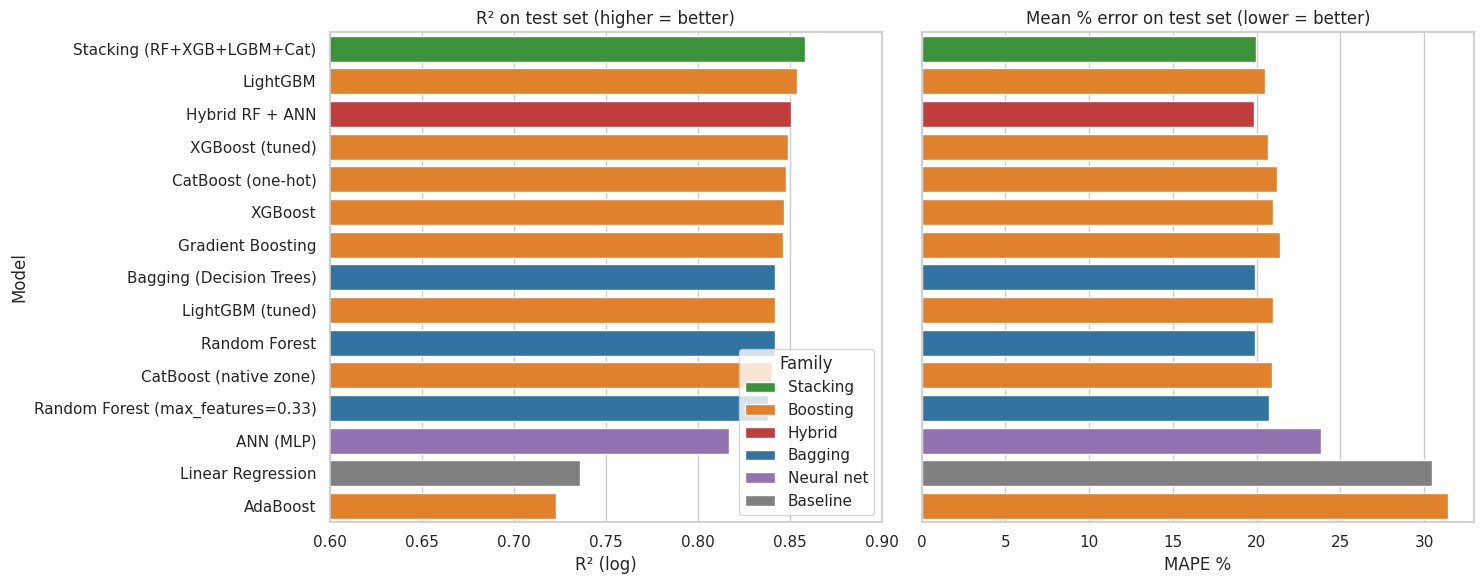

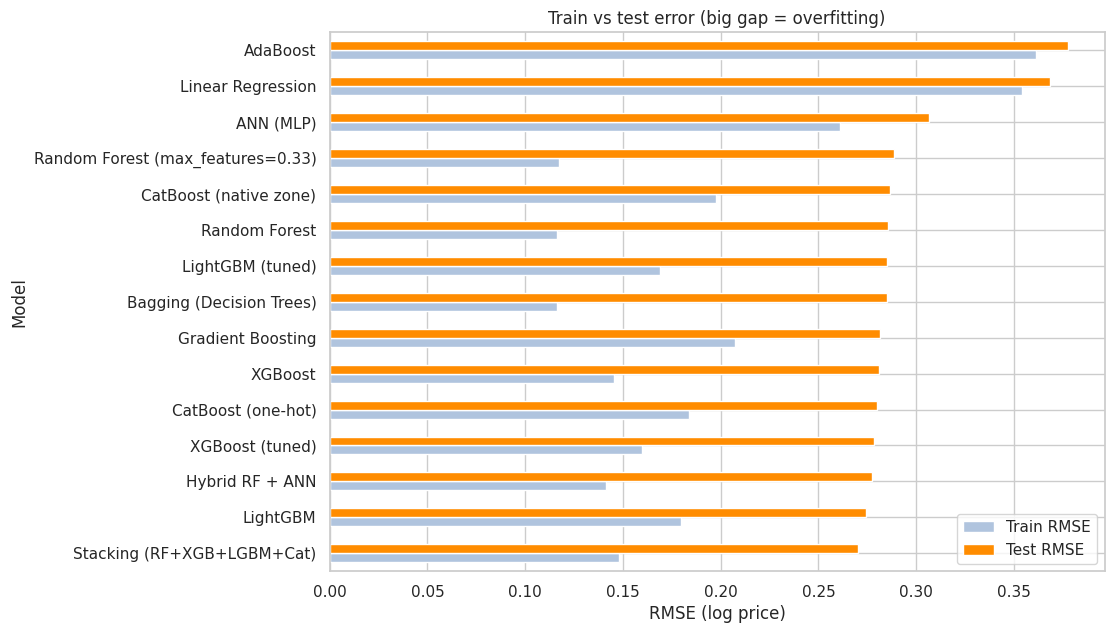

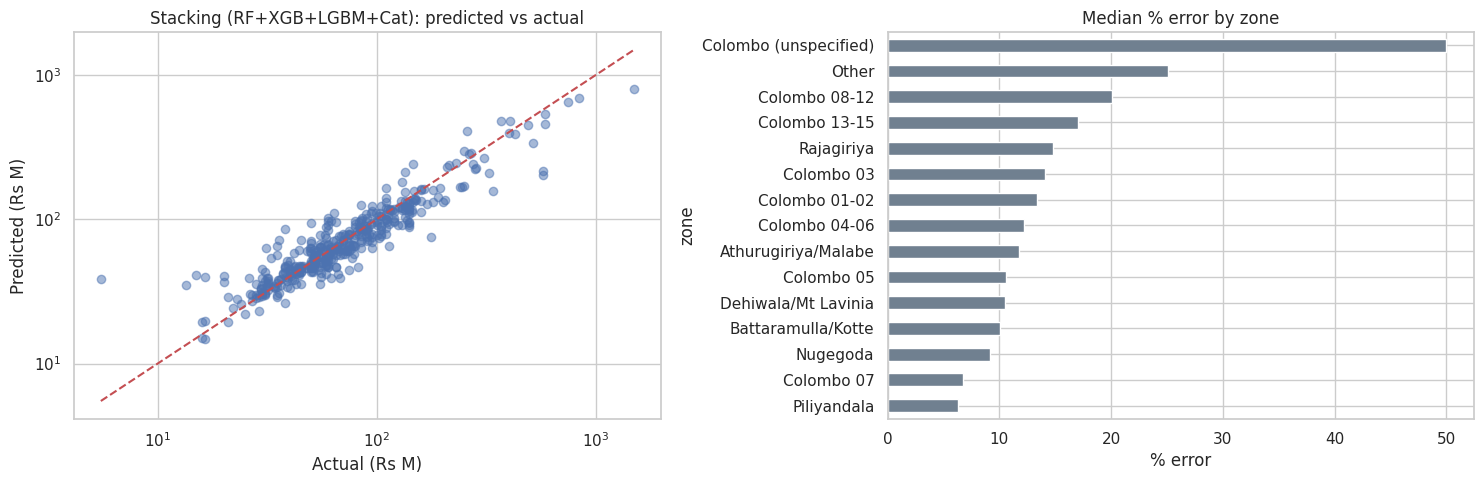

In [18]:
palette = {'Baseline': 'grey', 'Bagging': 'tab:blue', 'Boosting': 'tab:orange',
           'Stacking': 'tab:green', 'Neural net': 'tab:purple', 'Hybrid': 'tab:red'}

fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
sns.barplot(data=res, y='Model', x='R² (log)', hue='Family', dodge=False, palette=palette, ax=ax[0])
ax[0].set_xlim(0.6, 0.9); ax[0].set_title('R² on test set (higher = better)')
sns.barplot(data=res, y='Model', x='MAPE %', hue='Family', dodge=False, palette=palette, ax=ax[1], legend=False)
ax[1].set_title('Mean % error on test set (lower = better)')
plt.tight_layout(); plt.show()

# Overfitting check: train vs test RMSE
gap = []
for name in res['Model']:
    Xtr = Xc_train if 'native' in name else X_train
    gap.append({'Model': name,
                'Train RMSE': np.sqrt(mean_squared_error(y_train, models[name].predict(Xtr))),
                'Test RMSE': res.set_index('Model').loc[name, 'Test RMSE (log)']})
gap = pd.DataFrame(gap).set_index('Model')
gap.plot.barh(figsize=(10, 7), color=['lightsteelblue', 'darkorange'])
plt.title('Train vs test error (big gap = overfitting)'); plt.xlabel('RMSE (log price)'); plt.show()

# Best model: predicted vs actual, and error by zone
best = res.loc[0, 'Model']
actual, pred = np.exp(y_test) / 1e6, np.exp(preds[best]) / 1e6
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(actual, pred, alpha=0.5)
lims = [actual.min(), actual.max()]
ax[0].plot(lims, lims, 'r--'); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set(title=f'{best}: predicted vs actual', xlabel='Actual (Rs M)', ylabel='Predicted (Rs M)')

zone_err = (pd.DataFrame({'zone': df.loc[X_test.index, 'zone'],
                          'ape': (abs(pred - actual) / actual * 100).values})
            .groupby('zone')['ape'].median().sort_values())
zone_err.plot.barh(ax=ax[1], color='slategray')
ax[1].set(title='Median % error by zone', xlabel='% error')
plt.tight_layout(); plt.show()

7.3 Explaining the model with SHAP

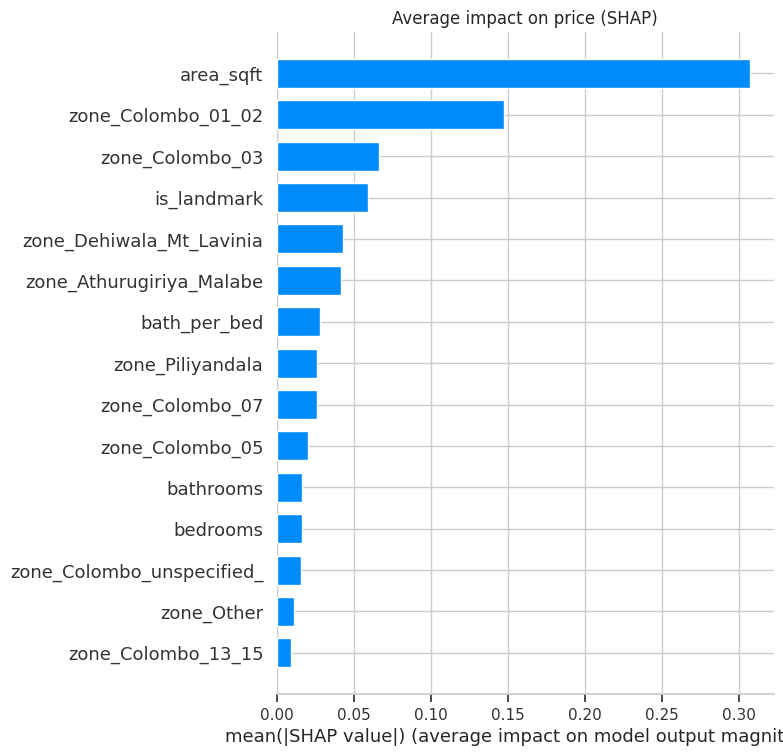

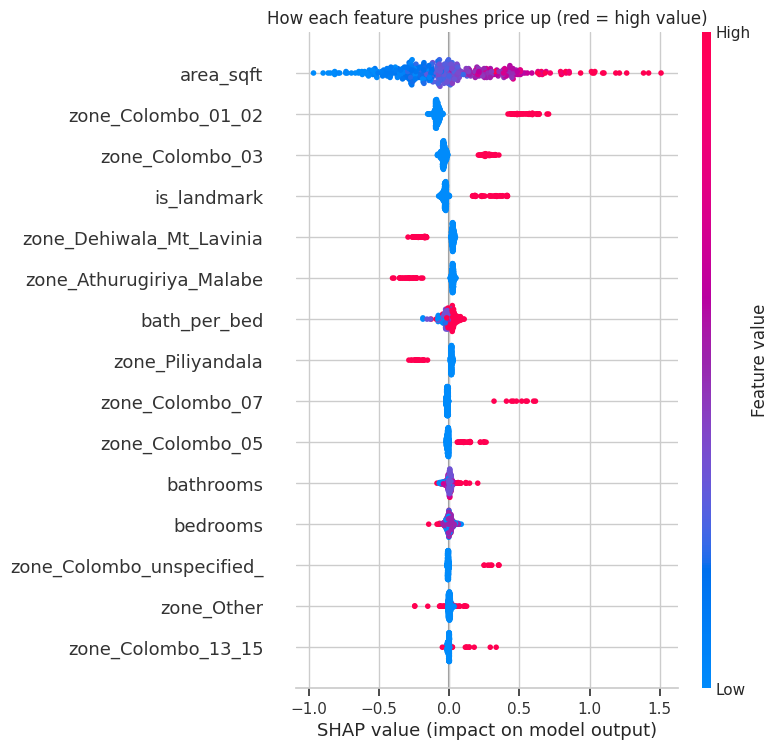

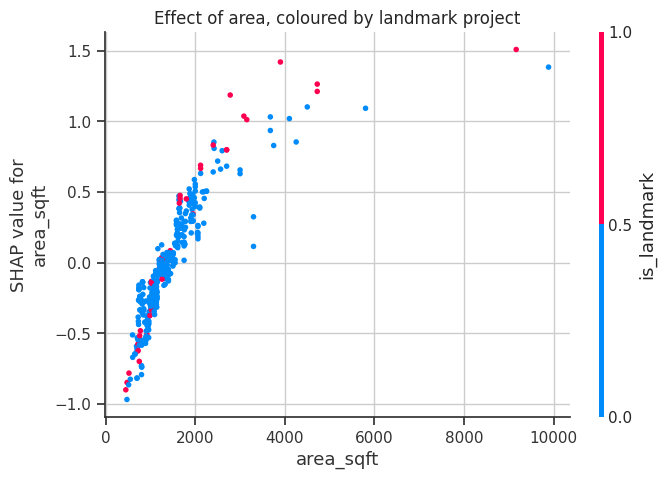

Stacking meta-model weights: {'RF': np.float64(0.293), 'XGB': np.float64(0.203), 'LGBM': np.float64(0.178), 'Cat': np.float64(0.326)}


In [19]:
import shap

explain_model = models['LightGBM (tuned)']
explainer = shap.TreeExplainer(explain_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, plot_type='bar', max_display=15, show=False)
plt.title('Average impact on price (SHAP)'); plt.show()

shap.summary_plot(shap_values, X_test, max_display=15, show=False)
plt.title('How each feature pushes price up (red = high value)'); plt.show()

shap.dependence_plot('area_sqft', shap_values, X_test, interaction_index='is_landmark', show=False)
plt.title('Effect of area, coloured by landmark project'); plt.show()

print('Stacking meta-model weights:',
      dict(zip(['RF', 'XGB', 'LGBM', 'Cat'], models['Stacking (RF+XGB+LGBM+Cat)'].final_estimator_.coef_.round(3))))

## 7.4 Interpretation of results

**1. Overall.** All ensembles clearly beat the linear baseline (R² 0.736, MAPE 30.5%). The best model,
Stacking, explains ~86% of the variance in log price with a typical error of ~20%. Given that the data
are *asking* prices posted by agents (not sale prices), ~20% error is close to the noise floor of the data.

**2. Bagging vs boosting.** Boosting models (R² 0.846–0.854) beat bagging (0.842). Bagging averages many
deep, independent trees, which mainly *reduces variance*; boosting builds shallow trees sequentially,
each correcting the last one's residuals, which *reduces bias*. The train-vs-test chart shows bagging
fits the training data almost perfectly (large gap), so its errors come from variance it cannot fully
average away on ~1,600 rows. Default sklearn Random Forest uses all features per split, so it was
identical to plain bagging; adding feature randomness (max_features=0.33) gave [ ].

**3. Boosting variants.** LightGBM/XGBoost/Gradient Boosting performed similarly (~0.85); tuning gave [ ].
AdaBoost was worst (0.723) because it exponentially up-weights badly-predicted listings — here mostly
mispriced or unusual ads — so it chases noise. CatBoost with native categories (0.840) did not beat
one-hot (0.848): with only one 15-level categorical, one-hot loses nothing, and CatBoost's target
statistics are noisy for small zones (35–60 listings).

**4. Stacking.** Stacking gave the best R² but only +0.004 over LightGBM, at ~80× the training time.
The base models are all tree ensembles trained on the same features, so their errors are highly
correlated — the meta-model has little independent information to combine. Meta-weights: [ ].

**5. Hybrid RF + ANN.** The ANN alone has lower R² (0.817) but the lowest rupee RMSE (Rs 41.3M), because
its smooth function extrapolates to very expensive units, whereas trees cannot predict above the highest
price seen in a leaf. RF and ANN make *different* errors, so blending them gave the lowest MAE of all
models (Rs 18.6M). This shows diversity matters more than adding more similar models.

**6. What drives price (SHAP).** [Top 3 features, e.g. area_sqft, is_landmark, zone_Colombo_01_02].
Larger area raises price but with diminishing returns; landmark projects (Cinnamon Life, Altair, Tri-Zen)
add a large premium at the same size; central zones (Colombo 1–7) add a premium over suburbs such as
Athurugiriya and Piliyandala. Bedrooms add little once area is known (they are 0.78 correlated).

**7. Limitations.** Asking prices ≠ transaction prices; ~1,100 duplicate re-posts removed suggests agent
bias; location extracted from ad text may be imperfect; Colombo-only, two-month snapshot (Aug–Sep);
no features for floor level, age, parking or amenities.

8.1 A lighter stacking model for deployment

In [20]:
stack_light = StackingRegressor(
    estimators=[('rf', RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED)),
                ('xgb', make_xgb()), ('lgbm', make_lgbm()), ('cat', make_cat())],
    final_estimator=RidgeCV(), cv=5, n_jobs=-1)
evaluate('Stacking (deploy, light RF)', 'Stacking', stack_light, cv=False)

Stacking (deploy, light RF) R²=0.858  MAE=Rs 19.9M  MAPE=20.1%


8.2 Save models, metadata and results

In [21]:
import joblib, os, sys, sklearn, xgboost, lightgbm, catboost

deploy_models = {
    'Stacking (best)':   stack_light,
    'LightGBM':          models['LightGBM'],
    'XGBoost (tuned)':   models['XGBoost (tuned)'],
    'CatBoost':          models['CatBoost (one-hot)'],
    'ANN (MLP)':         models['ANN (MLP)'],
    'Linear Regression': models['Linear Regression'],
}
joblib.dump(deploy_models, 'models.joblib', compress=3)

zone_cols = {z: 'zone_' + re.sub(r'[^A-Za-z0-9_]+', '_', z) for z in sorted(df['zone'].unique())}
assert all(c in X.columns for c in zone_cols.values()), 'zone column mismatch'

res = (pd.DataFrame(results).drop_duplicates('Model', keep='last')
       .sort_values('Test RMSE (log)').reset_index(drop=True))
res.round(3).to_csv('model_results.csv', index=False)

meta = {
    'columns': list(X.columns),
    'zone_cols': zone_cols,
    'keywords': list(KEYWORDS),
    'zone_median_price': df.groupby('zone')['price_lkr'].median().to_dict(),
    'mape': float(res.set_index('Model').loc['Stacking (deploy, light RF)', 'MAPE %']),
    'n_listings': len(df),
}
joblib.dump(meta, 'meta.joblib')

pd.DataFrame({'feature': X_test.columns, 'mean_abs_shap': np.abs(shap_values).mean(axis=0)}) \
  .sort_values('mean_abs_shap', ascending=False).to_csv('shap_importance.csv', index=False)

reqs = ['streamlit', f'pandas=={pd.__version__}', f'numpy=={np.__version__}',
        f'scikit-learn=={sklearn.__version__}', f'xgboost=={xgboost.__version__}',
        f'lightgbm=={lightgbm.__version__}', f'catboost=={catboost.__version__}',
        f'shap=={shap.__version__}']
open('requirements.txt', 'w').write('\n'.join(reqs) + '\n')

print('Python version (pick this on Streamlit Cloud):', sys.version.split()[0])
for f in ['models.joblib', 'meta.joblib', 'model_results.csv', 'shap_importance.csv', 'requirements.txt']:
    print(f'{f:<22} {os.path.getsize(f) / 1e6:.2f} MB')

Python version (pick this on Streamlit Cloud): 3.13.18
models.joblib          6.95 MB
meta.joblib            0.00 MB
model_results.csv      0.00 MB
shap_importance.csv    0.00 MB
requirements.txt       0.00 MB


In [1]:
from google.colab import files
for f in ['models.joblib', 'meta.joblib', 'model_results.csv', 'shap_importance.csv',
          'requirements.txt', 'apartments_clean.csv']:
    files.download(f)

FileNotFoundError: Cannot find file: models.joblib